In [5]:
!pip install openpyxl

  Obtaining dependency information for openpyxl from https://files.pythonhosted.org/packages/c0/da/977ded879c29cbd04de313843e76868e6e13408a94ed6b987245dc7c8506/openpyxl-3.1.5-py2.py3-none-any.whl.metadata
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Obtaining dependency information for et-xmlfile from https://files.pythonhosted.org/packages/c1/8b/5fe2cc11fee489817272089c4203e679c63b570a5aaeb18d852ae3cbba6a/et_xmlfile-2.0.0-py3-none-any.whl.metadata
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [38]:
df = pd.read_excel("../AI4ALL/student_dataset.xlsx")

In [17]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nFirst 5 rows:\n", df.head())

Shape: (10, 18)

Data types:
 student_id                            str
signup_date                datetime64[us]
last_active_date           datetime64[us]
age                                 int64
gender                                str
zip_code                            int64
education_level                       str
employment_status                     str
annual_income_usd                 float64
study_hours_per_week              float64
attendance_rate_pct                 int64
internet_speed_mbps               float64
device_type                           str
prior_python_experience               str
assessment_score                    int64
motivation_statement                  str
final_project_score                 int64
completed_program                     str
dtype: object

Missing values:
 student_id                 0
signup_date                0
last_active_date           0
age                        0
gender                     1
zip_code                   0
educatio

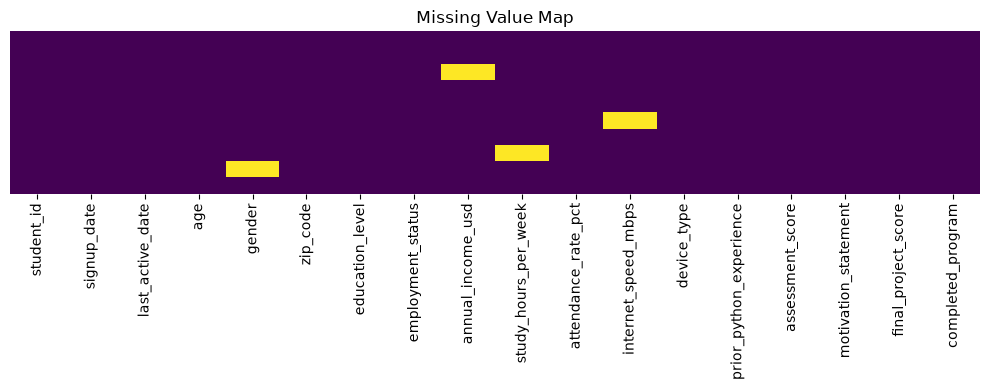

gender                  10.0
annual_income_usd       10.0
study_hours_per_week    10.0
internet_speed_mbps     10.0
dtype: float64


In [20]:
# Visualize missingness
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Value Map")
plt.tight_layout()
plt.show()

# Percentage missing per column
missing_pct = (df.isnull().sum() / len(df)) * 100
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

In [39]:
# CRITICAL: Create the flag BEFORE imputing, otherwise it will be all zeros
df["income_missing"] = df["annual_income_usd"].isnull().astype(int)

print("Income missing flag distribution:")
print(df["income_missing"].value_counts())
print(f"\nRows with missing income: {df['income_missing'].sum()}")

Income missing flag distribution:
income_missing
0    9
1    1
Name: count, dtype: int64

Rows with missing income: 1


In [40]:
# Unemployed students likely have ~0 income; impute 0 for them
unemployed_mask = df["employment_status"] == "Unemployed"
df.loc[unemployed_mask & df["annual_income_usd"].isna(), "annual_income_usd"] = 0

# Everyone else gets the median
df["annual_income_usd"] = df["annual_income_usd"].fillna(
    df["annual_income_usd"].median()
)

print(df[["student_id", "employment_status", "annual_income_usd", "income_missing"]])
print(f"\nRemaining nulls in income: {df['annual_income_usd'].isnull().sum()}")

  student_id employment_status  annual_income_usd  income_missing
0       S001         Part-time            42000.0               0
1       S002         Full-time            65000.0               0
2       S003        Unemployed                0.0               1
3       S004         Full-time          9999999.0               0
4       S005           Student            12000.0               0
5       S006           Retired            38000.0               0
6       S007        Gig Worker            54000.0               0
7       S008         Full-time            72000.0               0
8       S009         Part-time            28000.0               0
9       S010         Full-time           134000.0               0

Remaining nulls in income: 0


In [41]:
# Median is safer than mean when outliers exist
df["study_hours_per_week"] = df["study_hours_per_week"].fillna(
    df["study_hours_per_week"].median()
)

# Conditional median by device type for internet speed
df["internet_speed_mbps"] = df.groupby("device_type")["internet_speed_mbps"].transform(
    lambda s: s.fillna(s.median())
)
df["internet_speed_mbps"] = df["internet_speed_mbps"].fillna(
    df["internet_speed_mbps"].median()
)

# Categorical: mode
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])

print("Missing values after imputation:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\n(If empty above, all missing values are handled.)")

Missing values after imputation:
Series([], dtype: int64)

(If empty above, all missing values are handled.)


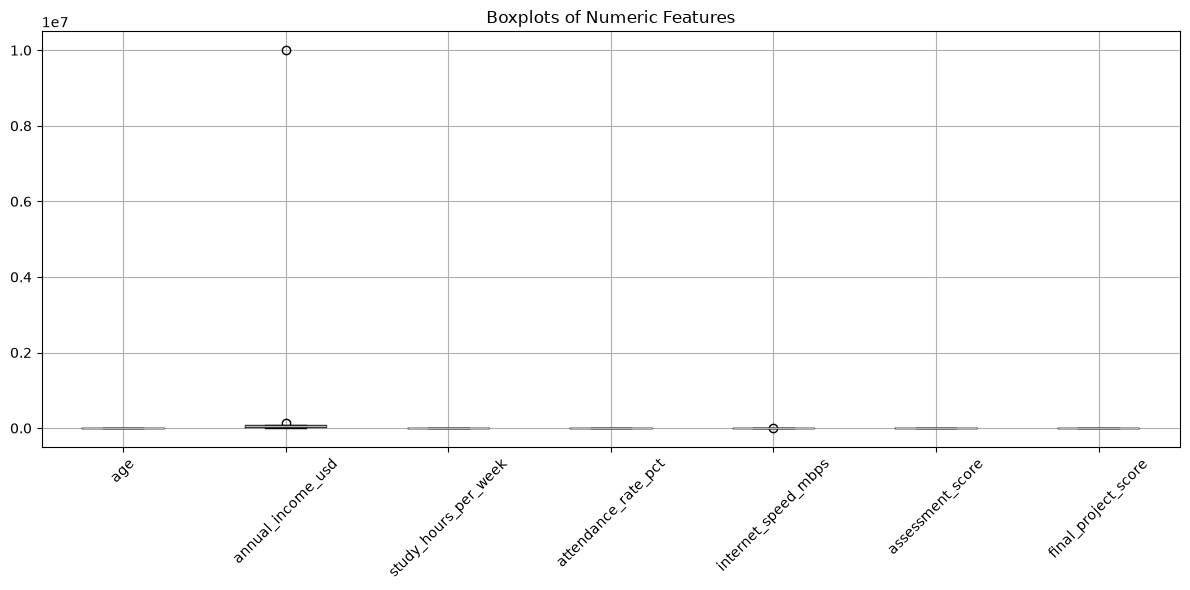

In [42]:
num_cols = ["age", "annual_income_usd", "study_hours_per_week",
            "attendance_rate_pct", "internet_speed_mbps",
            "assessment_score", "final_project_score"]

plt.figure(figsize=(12, 6))
df[num_cols].boxplot(rot=45)
plt.title("Boxplots of Numeric Features")
plt.tight_layout()
plt.show()

In [43]:
def find_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return series[(series < lower) | (series > upper)]

print("Income outliers (1.5x IQR):")
print(find_outliers_iqr(df["annual_income_usd"]))

print("\nInternet speed outliers (1.5x IQR):")
print(find_outliers_iqr(df["internet_speed_mbps"]))

Income outliers (1.5x IQR):
3    9999999.0
9     134000.0
Name: annual_income_usd, dtype: float64

Internet speed outliers (1.5x IQR):
4    300.0
Name: internet_speed_mbps, dtype: float64


In [44]:
# detect outliers with z score 
income_series = df["annual_income_usd"].dropna()
z_scores = np.abs(stats.zscore(income_series))

print("Z-score > 3 outliers:")
outlier_indices = income_series.index[z_scores > 3]
if len(outlier_indices) > 0:
    print(df.loc[outlier_indices, ["student_id", "annual_income_usd"]])
else:
    print("None detected — the $9.99M outlier inflates standard deviation,")
    print("making the 3-sigma threshold too wide to catch anything.")

Z-score > 3 outliers:
None detected — the $9.99M outlier inflates standard deviation,
making the 3-sigma threshold too wide to catch anything.


In [45]:
# treat the income outlier
# Flag the outlier (preserves information)
Q1, Q3 = df["annual_income_usd"].quantile([0.25, 0.75])
upper_fence = Q3 + 1.5 * (Q3 - Q1)
df["income_outlier_flag"] = (df["annual_income_usd"] > upper_fence).astype(int)

# Winsorize at the 99th percentile (safer than deleting the row)
cap = df["annual_income_usd"].quantile(0.99)
df["annual_income_usd"] = df["annual_income_usd"].clip(upper=cap)

print("Income after capping:")
print(df[["student_id", "annual_income_usd", "income_outlier_flag"]])
print(f"\nMax income now: ${df['annual_income_usd'].max():,.2f}")

Income after capping:
  student_id  annual_income_usd  income_outlier_flag
0       S001           42000.00                    0
1       S002           65000.00                    0
2       S003               0.00                    0
3       S004         9112059.09                    1
4       S005           12000.00                    0
5       S006           38000.00                    0
6       S007           54000.00                    0
7       S008           72000.00                    0
8       S009           28000.00                    0
9       S010          134000.00                    1

Max income now: $9,112,059.09


In [46]:
# standardize ZIP codes
def clean_zip(val):
    if pd.isna(val):
        return np.nan
    s = "".join(ch for ch in str(val).split("-")[0] if ch.isdigit())
    return s.zfill(5) if s else np.nan

df["zip_code"] = df["zip_code"].apply(clean_zip)

print("Cleaned ZIP codes:")
print(df["zip_code"].tolist())

Cleaned ZIP codes:
['10027', '60614', '94107', '30301', '77005', '02139', '10027', '90089', '33109', '15213']


In [48]:
# parse dates and dervive days_active
df["signup_date"] = pd.to_datetime(df["signup_date"], errors="coerce", format="mixed")
df["last_active_date"] = pd.to_datetime(df["last_active_date"], errors="coerce", format="mixed")

df["days_active"] = (df["last_active_date"] - df["signup_date"]).dt.days

print(f"Unparseable signup dates: {df['signup_date'].isna().sum()}")
print(f"Unparseable last_active dates: {df['last_active_date'].isna().sum()}")
print("\ndays_active stats:")
print(df["days_active"].describe())

Unparseable signup dates: 0
Unparseable last_active dates: 0

days_active stats:
count    10.000000
mean     51.500000
std      12.367071
min      34.000000
25%      41.500000
50%      52.000000
75%      61.000000
max      68.000000
Name: days_active, dtype: float64


In [49]:
# engineer text features 
df["motivation_length"] = df["motivation_statement"].str.len()
df["motivation_word_count"] = df["motivation_statement"].str.split().str.len()
df["motivation_avg_word_len"] = (
    df["motivation_length"] / df["motivation_word_count"]
).round(2)

# Keyword flags for high-signal terms
keywords = ["ai", "machine learning", "career", "build", "project", "ethics"]
for kw in keywords:
    col = f"motiv_{kw.replace(' ', '_')}"
    df[col] = df["motivation_statement"].str.lower().str.contains(kw).astype(int)

print(df[["student_id", "motivation_length", "motivation_word_count",
          "motivation_avg_word_len"]])

  student_id  motivation_length  motivation_word_count  \
0       S001                 41                      7   
1       S002                 33                      5   
2       S003                 38                      5   
3       S004                 25                      4   
4       S005                 42                      6   
5       S006                 37                      6   
6       S007                 37                      6   
7       S008                 30                      4   
8       S009                 29                      4   
9       S010                 38                      5   

   motivation_avg_word_len  
0                     5.86  
1                     6.60  
2                     7.60  
3                     6.25  
4                     7.00  
5                     6.17  
6                     6.17  
7                     7.50  
8                     7.25  
9                     7.60  


In [50]:
# encode ordinal: education_level
edu_order = {
    "High School": 1,
    "Some College": 2,
    "Bachelors": 3,
    "Masters": 4,
    "PhD": 5
}

df["education_level_enc"] = df["education_level"].map(edu_order)
df = df.drop(columns=["education_level"])

print(df[["student_id", "education_level_enc"]])
print(f"\nAny unmapped (NaN)? {df['education_level_enc'].isnull().sum()}")

  student_id  education_level_enc
0       S001                    3
1       S002                    1
2       S003                    4
3       S004                    3
4       S005                    2
5       S006                    1
6       S007                    3
7       S008                    4
8       S009                    3
9       S010                    5

Any unmapped (NaN)? 0
